
[notice] A new release of pip is available: 23.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.
Dataset loaded: (72843, 19)
Columns: ['UserID', 'ChargerID', 'ChargerCompany', 'Location', 'ChargerType', 'StartDay', 'StartTime', 'EndDay', 'EndTime', 'StartDatetime', 'EndDatetime', 'Duration', 'Demand', 'Hour', 'Day', 'Month', 'DayOfWeek', 'IsWeekend', 'TimeOfDay']

Features used: ['ChargerCompany', 'Location', 'ChargerType', 'Hour', 'Day', 'Month', 'DayOfWeek', 'IsWeekend', 'TimeOfDay']
Target: Demand
Number of records: 72843

Training records: 58274
Testing records: 14569

Linear Regression
MAE:  9.8296
RMSE: 12.8919
R²:   0.0965

Random Forest
MAE:  10.4050
RMSE: 13.8390
R²:   -0.0411

MODEL COMPARISON


,Model,MAE,RMSE,R2
0,Linear Regression,9.829579,12.891856,0.096508
1,Random Forest,10.404999,13.838973,-0.041121


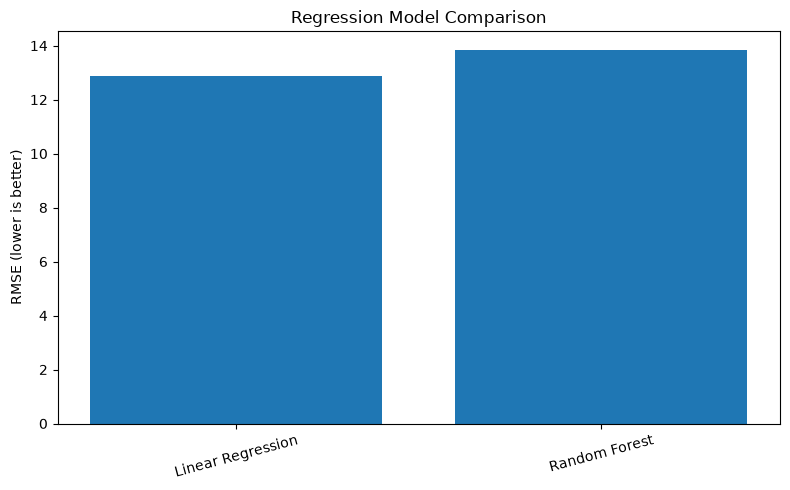


Best model: Linear Regression
Saved model to: c:\Users\Shyamsekar\OneDrive\Desktop\EV_Charging_Demand_Project\models\best_regression_model.joblib
Regression analysis completed!


In [1]:

# ============================================================
# FILE 2: EV CHARGING DEMAND REGRESSION
# ============================================================

# STEP 1: INSTALL REQUIRED LIBRARIES
%pip install pandas numpy scikit-learn matplotlib joblib

# STEP 2: IMPORT LIBRARIES
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

# STEP 3: FIND PROJECT FOLDER
ROOT = Path.cwd()

if ROOT.name == "notebooks":
    ROOT = ROOT.parent

DATA_PATH = ROOT / "data" / "cleaned_charging_data.csv"
MODEL_DIR = ROOT / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# STEP 4: LOAD CLEANED DATA
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Cannot find {DATA_PATH}. Run File 1 successfully first."
    )

df = pd.read_csv(DATA_PATH)

print("Dataset loaded:", df.shape)
print("Columns:", df.columns.tolist())

# STEP 5: CHECK TARGET
TARGET = "Demand"

if TARGET not in df.columns:
    raise ValueError(
        "Demand column not found. Check the dataset column names."
    )

df[TARGET] = pd.to_numeric(df[TARGET], errors="coerce")
df = df.dropna(subset=[TARGET]).copy()

# STEP 6: SELECT FEATURES
# Exclude the target and raw timestamps.
# Keep only useful features that actually exist in the dataset.
candidate_features = [
    "ChargerCompany",
    "Location",
    "ChargerType",
    "Hour",
    "Day",
    "Month",
    "DayOfWeek",
    "IsWeekend",
    "TimeOfDay",
]

features = [c for c in candidate_features if c in df.columns]

if not features:
    raise ValueError(
        "No expected feature columns were found. "
        "Inspect the printed column names and update candidate_features."
    )

X = df[features].copy()
y = df[TARGET].copy()

print("\nFeatures used:", features)
print("Target: Demand")
print("Number of records:", len(X))

# STEP 7: IDENTIFY NUMERIC AND CATEGORICAL FEATURES
numeric_features = X.select_dtypes(
    include=["number", "bool"]
).columns.tolist()

categorical_features = [
    c for c in X.columns if c not in numeric_features
]

# STEP 8: PREPROCESS FEATURES
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
])

transformers = []

if numeric_features:
    transformers.append(
        ("numeric", numeric_pipeline, numeric_features)
    )

if categorical_features:
    transformers.append(
        ("categorical", categorical_pipeline, categorical_features)
    )

preprocessor = ColumnTransformer(transformers=transformers)

# STEP 9: SPLIT DATA INTO TRAINING AND TESTING SETS
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
)

print("\nTraining records:", len(X_train))
print("Testing records:", len(X_test))

# STEP 10: TRAIN AND EVALUATE MODELS
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1,
    ),
}

trained_models = {}
results = []

for name, estimator in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", estimator),
    ])

    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    trained_models[name] = pipeline

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
    })

    print(f"\n{name}")
    print(f"MAE:  {mae:.4f}")
    print(f"RMSE: {rmse:.4f}")
    print(f"R²:   {r2:.4f}")

# STEP 11: COMPARE MODELS
results_df = pd.DataFrame(results).sort_values("RMSE")

print("\nMODEL COMPARISON")
display(results_df)

results_df.to_csv(
    ROOT / "models" / "regression_results.csv",
    index=False,
)

# STEP 12: VISUALIZE MODEL PERFORMANCE
plt.figure(figsize=(8, 5))
plt.bar(results_df["Model"], results_df["RMSE"])
plt.title("Regression Model Comparison")
plt.ylabel("RMSE (lower is better)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# STEP 13: SAVE THE BEST MODEL
best_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_name]

model_path = MODEL_DIR / "best_regression_model.joblib"
joblib.dump(best_model, model_path)

print("\nBest model:", best_name)
print("Saved model to:", model_path)
print("Regression analysis completed!")
